# Wine 데이터셋 분석
**목표:** 와인 데이터의 변수 특성 및 분포 분석

- 데이터: `sklearn.datasets.load_wine` (UCI Wine, 178개 샘플, 13개 화학 성분, 3개 품종 클래스)
- 구조파악 => 결측치 / 이상치 점검 => 변수 분포 => 클래스별 비교 => 상관관계 => 스케일링 / PCA
- 참고: https://wikidocs.net/217157

## 환경 설정

In [1]:
# 한글 폰트 설정 (Colab)
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# numpy, pandas, matplotlib, sklearn 사용
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 폰트 설정 및 테마 설정
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})
pd.set_option('display.max_columns', None)

## 1. 데이터 로드

In [2]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True) # data load (sklearn 내장)
df = wine.frame.copy()

df['class_name'] = df['target'].map(dict(enumerate(wine.target_names)))
# 0, 1, 2 => 'class_0', 'class_1', 'class_2' 매핑
# 숫자 라벨은 보기 어려우니 문자열 라벨 컬럼(class_name)을 따로 만들어 둠 (target 은 상관관계 계산용으로 유지)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
print(wine.DESCR[:1500])
# 데이터셋 설명 확인 (13개 화학 성분 = feature, 3개 품종 = class)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

## 2. 데이터 구조 파악

In [4]:
print('shape:', df.shape) # (178, 15) : feature 13 + target + class_name, record(row) 178
df.info()

# 수치형 feature 13개는 모두 float64, target 은 int, class_name 은 object

shape: (178, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    f

In [5]:
df.describe().T
# 평균, 표준편차, 최소/최대값 등 분포 확인 (전치행렬)
# 변수마다 값의 범위가 크게 다름 (proline 은 수백~천 단위, hue 는 1 안팎)
# => 스케일링 필요O

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


class_name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


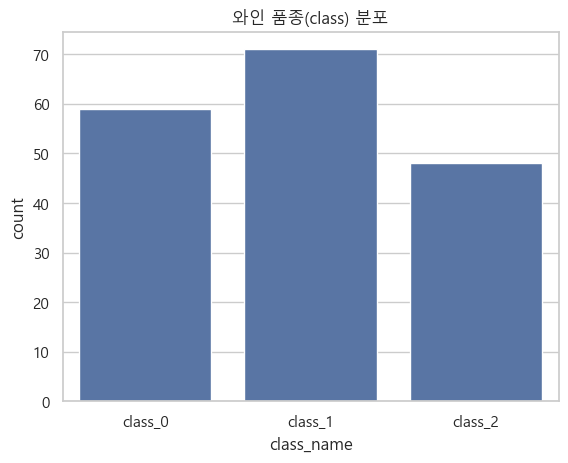

In [6]:
print(df['class_name'].value_counts())
sns.countplot(data=df, x='class_name')
plt.title('와인 품종(class) 분포')
plt.show()

# 품종별 데이터 개수 확인 (59 / 71 / 48 로 크게 치우치거나 하진 않음)

## 3. 결측치, 이상치, 중복값 분석 및 처리

In [7]:
print('결측치:\n', df.isnull().sum())
print('\n중복 행 수:', df.duplicated().sum())

# 결측치, 중복값 개수 계산 => 둘 다 0 (별도 처리 필요 없음)

결측치:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
class_name                      0
dtype: int64

중복 행 수: 0


In [8]:
# IQR 이상치 (IQR = Q_3 - Q_1 통계적 이상치판별지표)
features = wine.feature_names # features 에 각 col 담아주기 (순회를 위한 변수)

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c]) for c in features}, name='outliers').sort_values(ascending=False)

# col순회하며 Q1-(1.5*IQR)~Q3+(1.5*IQR) 범위 벗어나는 값 개수 탐지
# 일부 feature 에만 소수 존재, 178개 중 몇 개 수준이라 제거X (데이터 자체가 적음)

magnesium                       4
alcalinity_of_ash               4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
nonflavanoid_phenols            0
flavanoids                      0
od280/od315_of_diluted_wines    0
proline                         0
Name: outliers, dtype: int64

In [9]:
# 이상치를 품종(class)별로도 확인 (피드백 반영)
# 전체 기준 IQR 과 달리, 각 품종 안에서 Q1-(1.5*IQR)~Q3+(1.5*IQR) 벗어나는 값 개수 계산
out_by_class = df.groupby('class_name')[features].agg(iqr_outliers).T
out_by_class['전체 기준'] = pd.Series({c: iqr_outliers(df[c]) for c in features})
out_by_class['품종별 합계'] = out_by_class[['class_0', 'class_1', 'class_2']].sum(axis=1)
out_by_class.sort_values('품종별 합계', ascending=False)

# 품종 안에서 보면 전체 기준보다 이상치가 더 많이 잡히는 변수가 있음 (malic_acid 3 => 16, proanthocyanins 2 => 14)
# 품종마다 값의 중심이 달라서 전체로 볼 땐 가려져 있던 값이 드러나는 것
# 단, 품종별 표본이 48~71개로 적어서 제거하지 않고 그대로 둠 (이상치를 클래스별로 보는 관점을 확인한 것에 의미)

class_name,class_0,class_1,class_2,전체 기준,품종별 합계
malic_acid,9,7,0,3,16
proanthocyanins,4,8,2,2,14
alcalinity_of_ash,3,4,0,4,7
nonflavanoid_phenols,4,0,1,0,5
magnesium,0,5,0,4,5
color_intensity,1,4,0,4,5
total_phenols,2,0,2,0,4
ash,1,2,0,3,3
alcohol,0,3,0,0,3
flavanoids,0,1,1,0,2


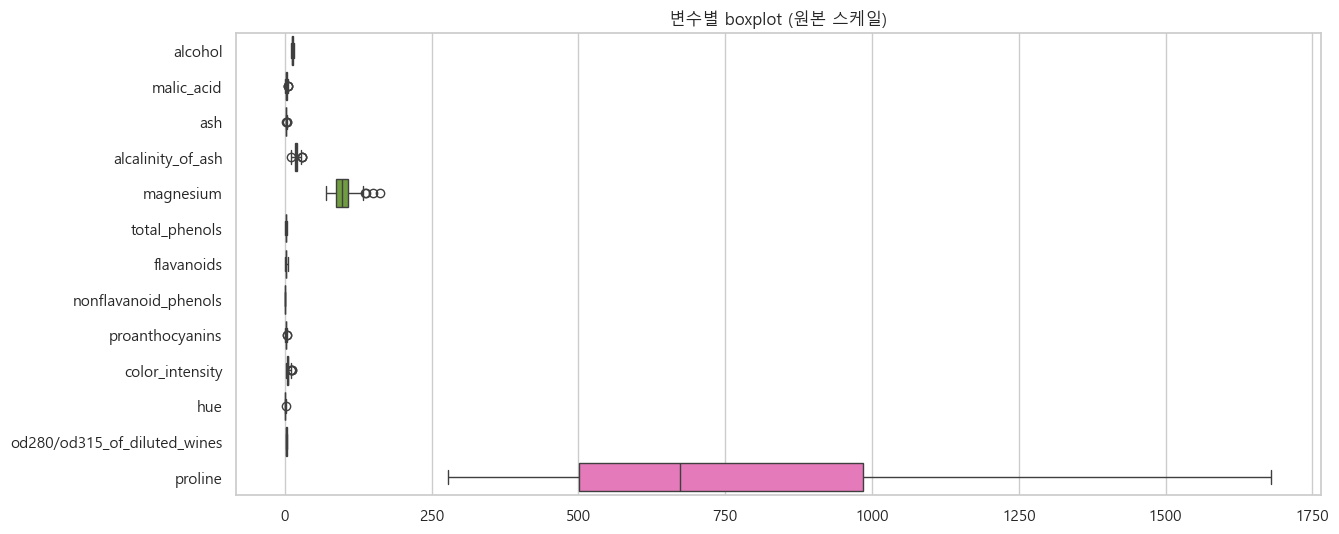

In [10]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df[features], orient='h')
plt.title('변수별 boxplot (원본 스케일)')
plt.show()

# 변수별 값 분포 시각화 (boxplot)
# proline 이 압도적으로 큰 값 범위를 가져서 다른 feature 는 거의 한 줄로 보임 => 스케일링 필요

## 4. 변수 분포

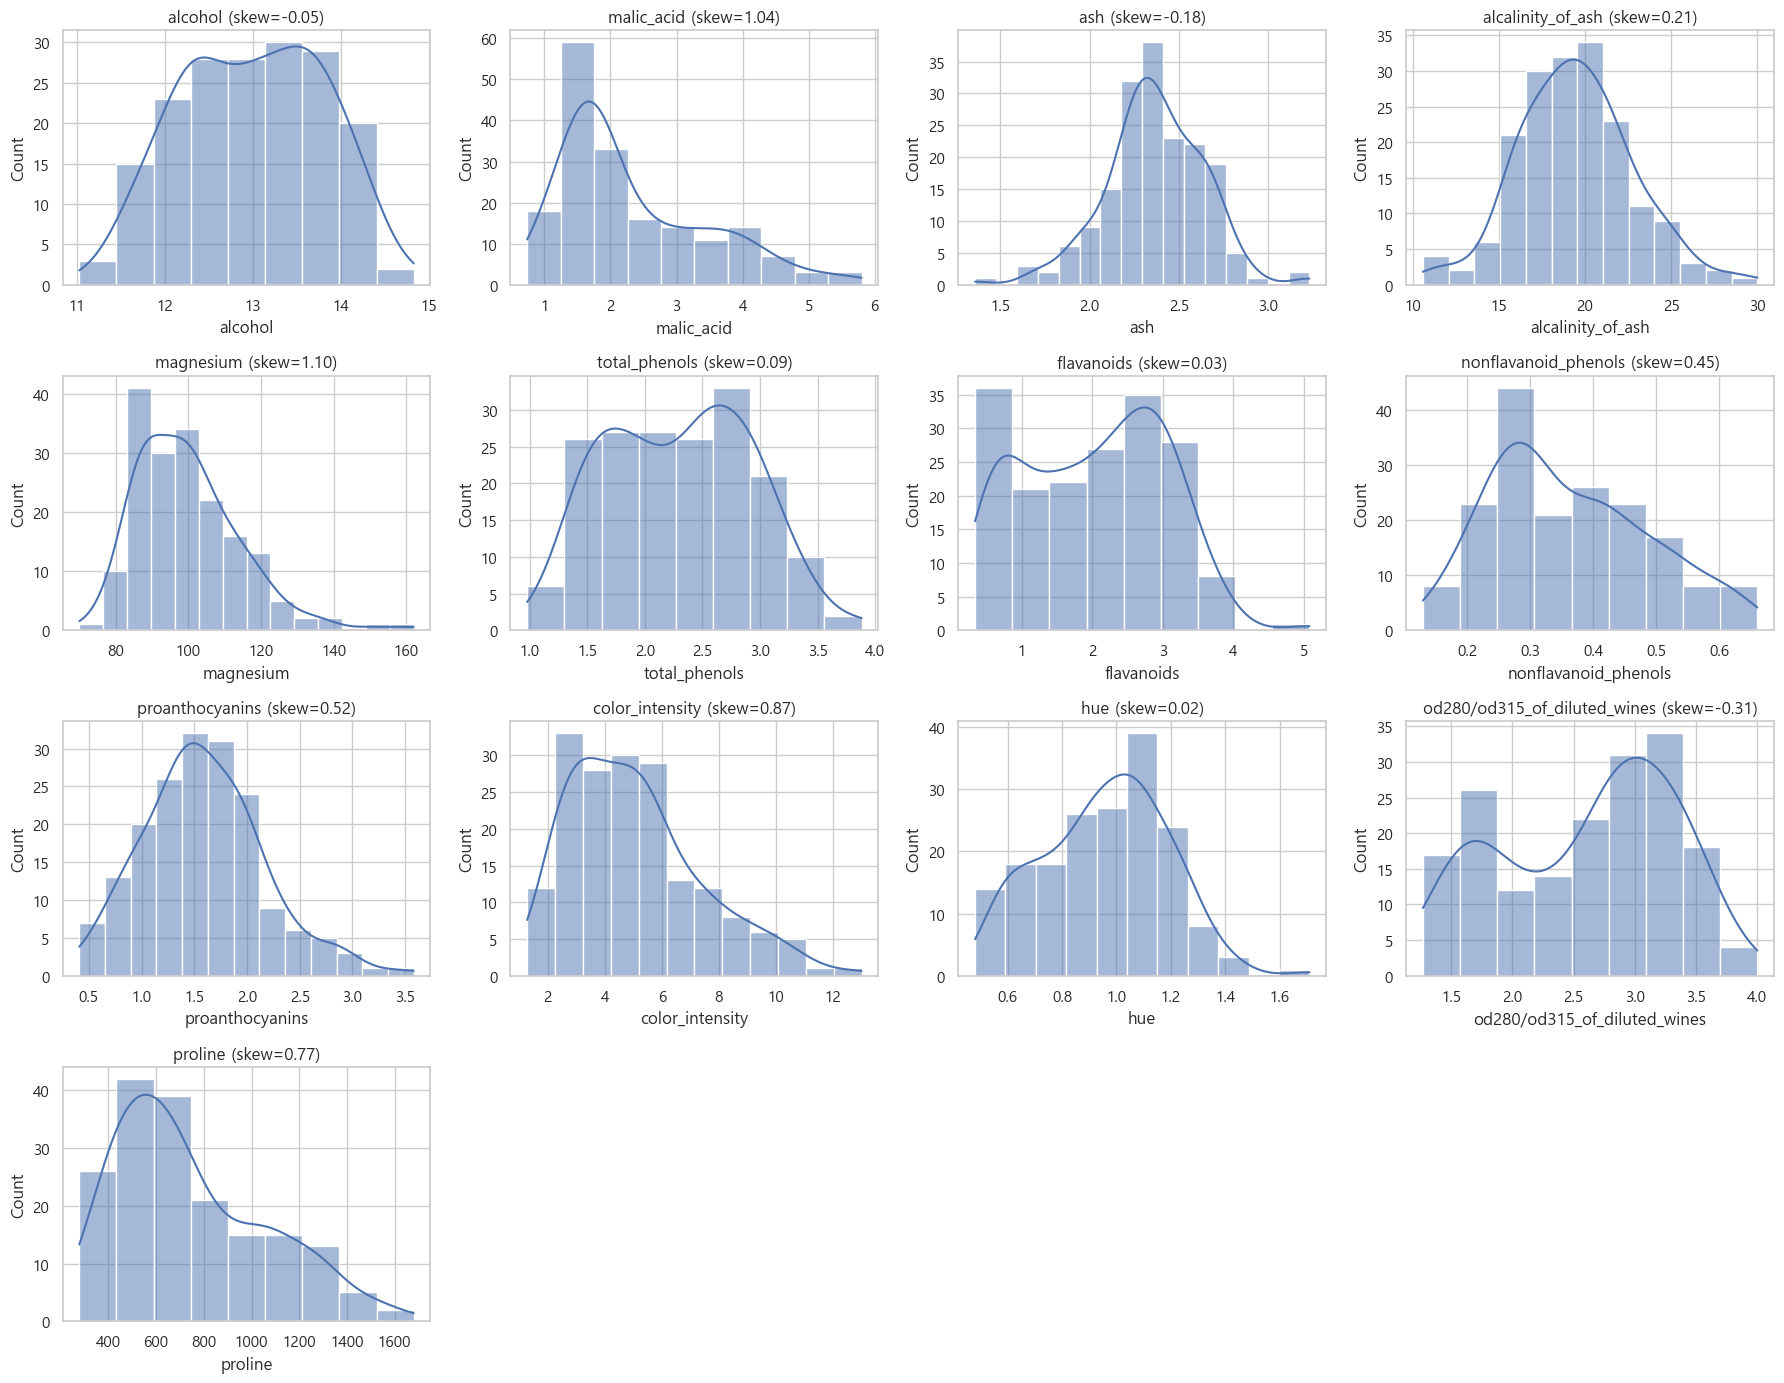

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'{col} (skew={df[col].skew():.2f})')
for ax in axes.flat[len(features):]:
    ax.remove() # 13개만 그리므로 남는 칸 제거
plt.tight_layout()
plt.show()

# feature 별 histplot + kde
# 대체로 종모양에 가깝지만 malic_acid, proline 등은 오른쪽으로 치우친 모양

In [12]:
df[features].skew().sort_values(key=abs, ascending=False)

# 왜도(skewness) 절댓값이 큰 순서로 정렬 (0에 가까울수록 좌우 대칭)
# 값이 클수록 한쪽으로 치우친 분포 => 필요시 로그 변환 후보

magnesium                       1.098191
malic_acid                      1.039651
color_intensity                 0.868585
proline                         0.767822
proanthocyanins                 0.517137
nonflavanoid_phenols            0.450151
od280/od315_of_diluted_wines   -0.307285
alcalinity_of_ash               0.213047
ash                            -0.176699
total_phenols                   0.086639
alcohol                        -0.051482
flavanoids                      0.025344
hue                             0.021091
dtype: float64

,원본 skew,log1p 후 skew
magnesium,1.10,0.61
malic_acid,1.04,0.53
color_intensity,0.87,0.10
proline,0.77,0.09


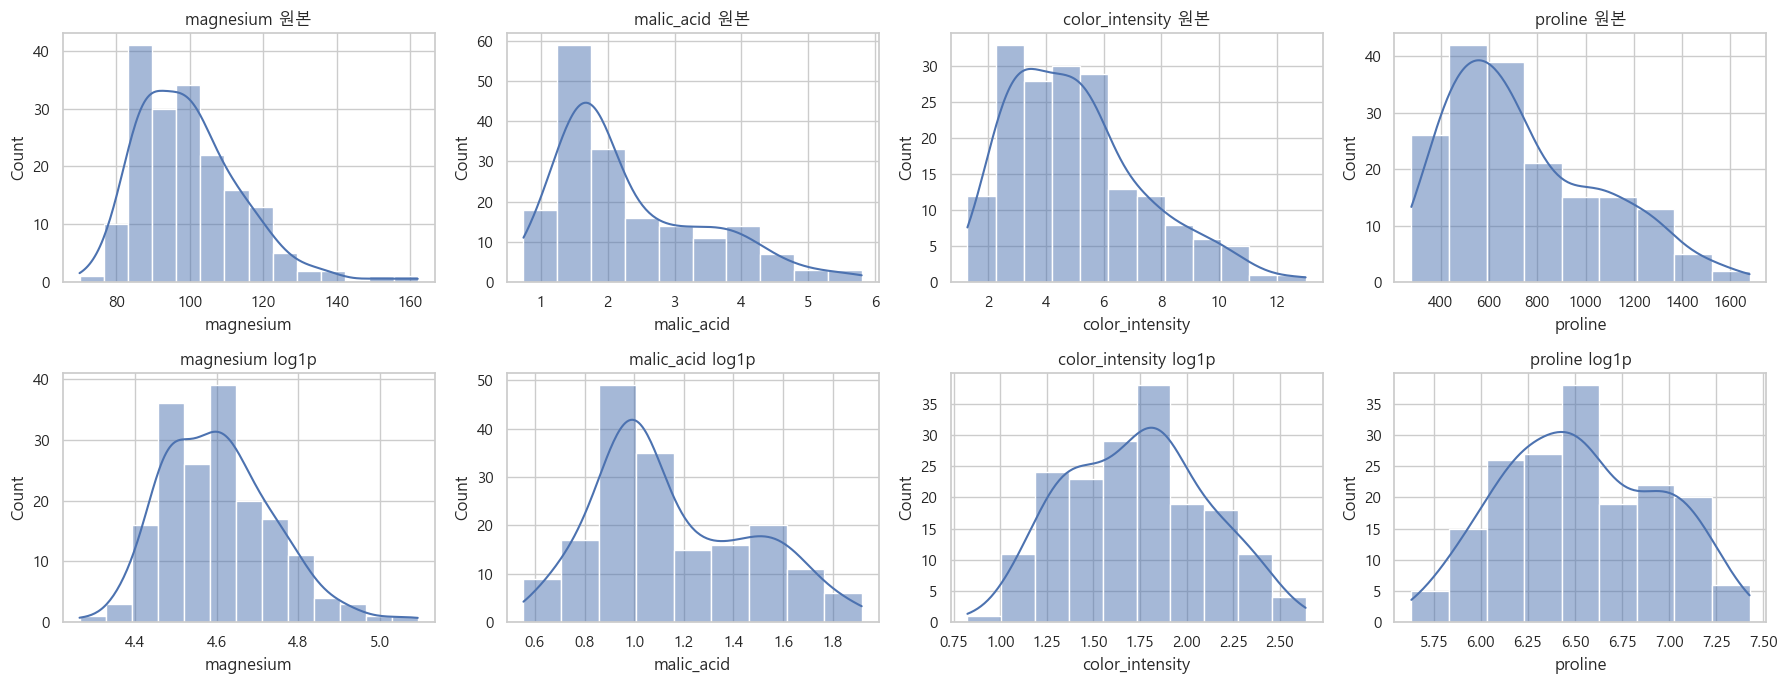

In [13]:
# 로그 변환 효과 확인 (피드백 반영)
# 왜도 절댓값 상위 4개 feature 에 log1p 적용 => 전후 왜도 비교 (wine 의 feature 는 모두 0 이상이라 log1p 사용 가능)
skew_top = df[features].skew().abs().sort_values(ascending=False).head(4).index

skew_cmp = pd.DataFrame({
    '원본 skew': df[skew_top].skew(),
    'log1p 후 skew': np.log1p(df[skew_top]).skew()
}).round(2)
display(skew_cmp)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(skew_top):
    sns.histplot(df[col], kde=True, ax=axes[0, j]); axes[0, j].set_title(f'{col} 원본')
    sns.histplot(np.log1p(df[col]), kde=True, ax=axes[1, j]); axes[1, j].set_title(f'{col} log1p')
plt.tight_layout()
plt.show()

# 위쪽 원본 / 아래쪽 log1p 적용 후 분포 비교
# 상위 4개 모두 왜도가 줄어듦 (color_intensity 0.87 => 0.10, proline 0.77 => 0.09 로 거의 대칭)
# 다만 원래 왜도가 1 안팎으로 아주 크지 않아서 변환이 필수는 아님
# 이미 대칭인 변수에 적용하면 오히려 반대로 치우칠 수 있으므로 왜도 큰 변수에만 선택적으로 적용

## 5. 클래스별 변수 비교

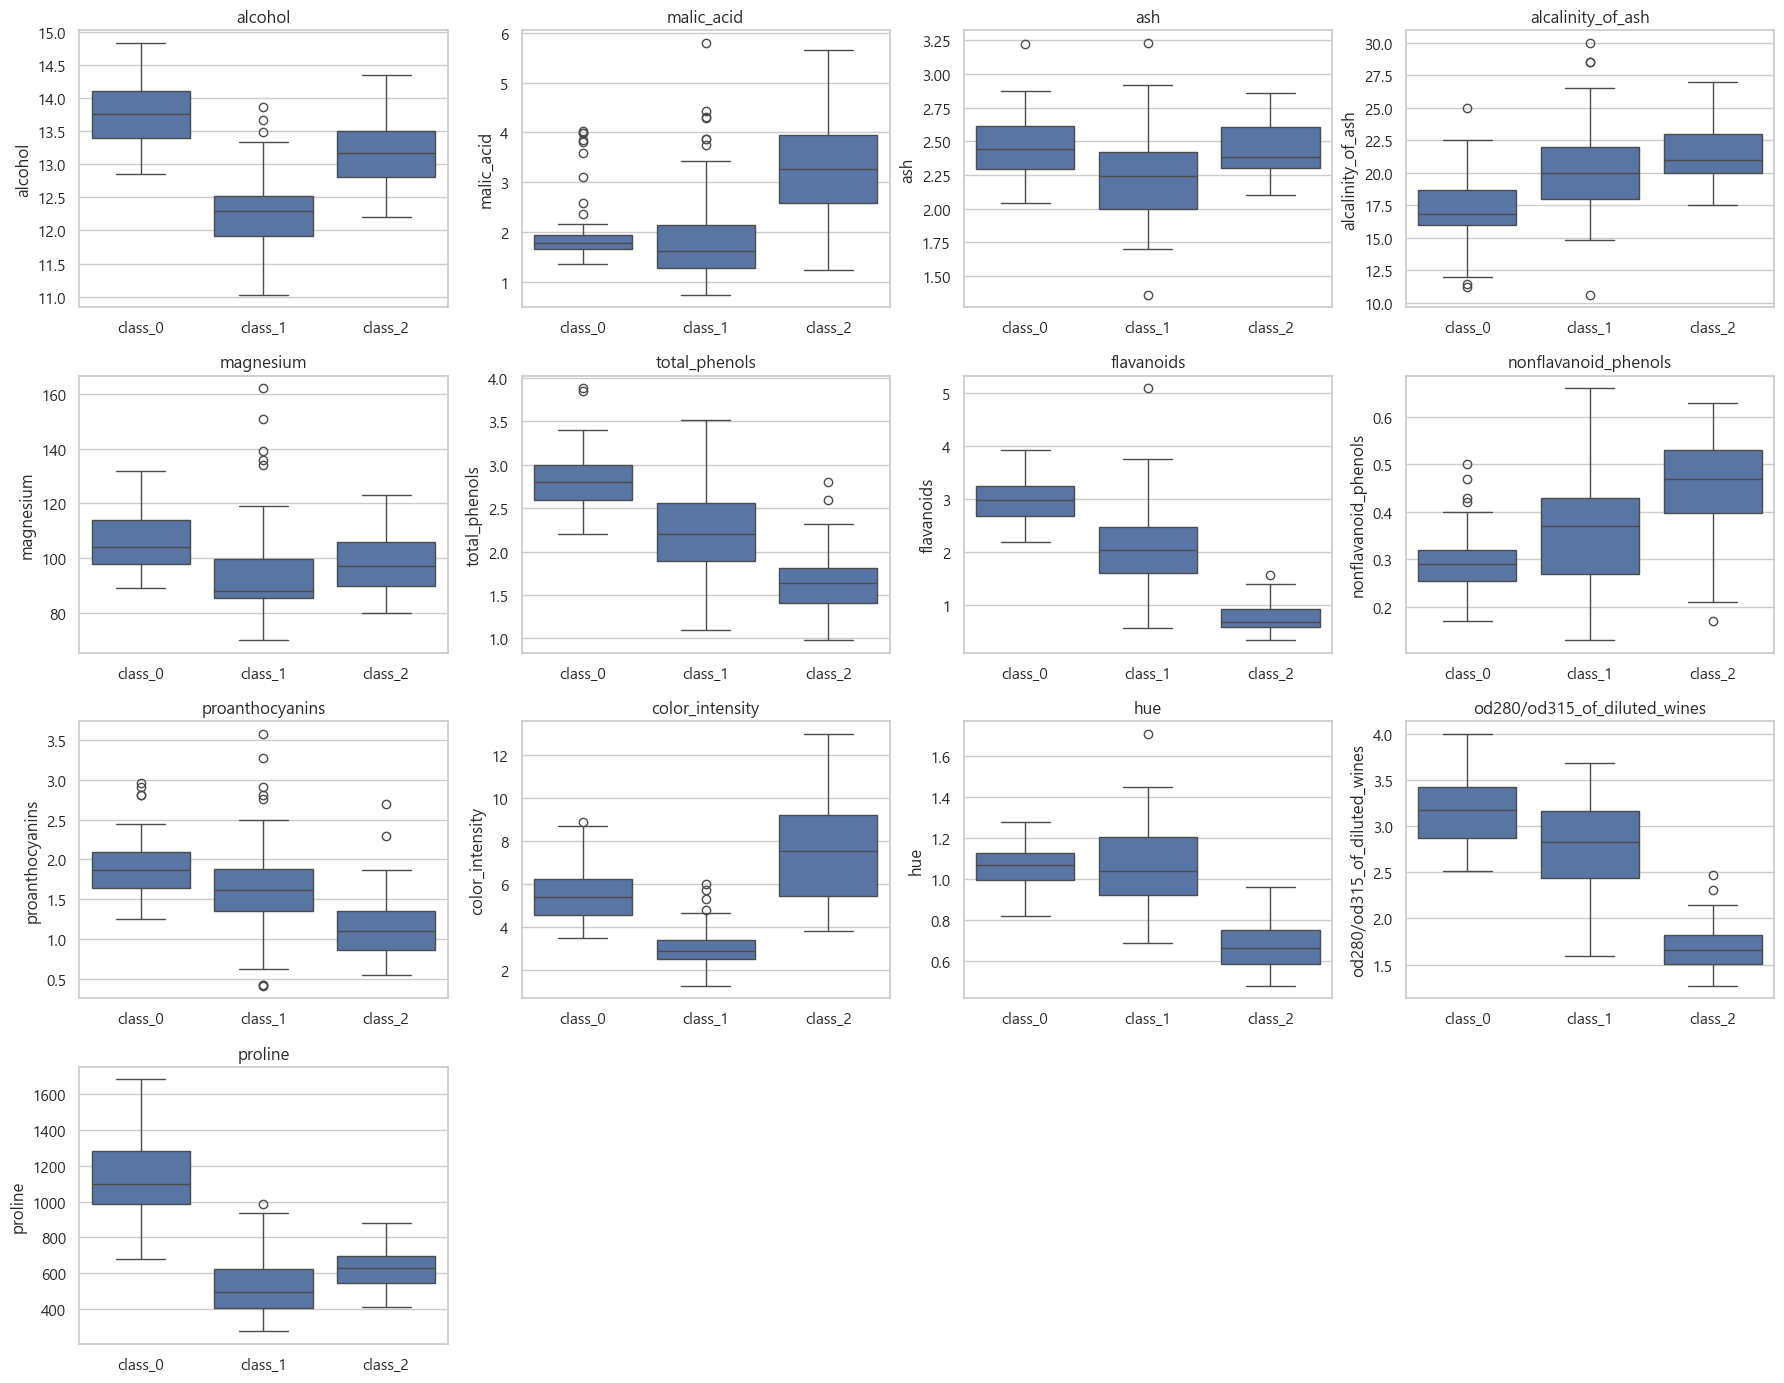

In [14]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='class_name', y=col, ax=ax)
    ax.set_title(col); ax.set_xlabel('')
for ax in axes.flat[len(features):]:
    ax.remove()
plt.tight_layout()
plt.show()

# 품종(class)별로 각 feature 값이 어떻게 다른지 boxplot 으로 비교
# flavanoids, proline, color_intensity, alcohol 등은 품종간 차이가 뚜렷해 분류에 유리해 보임
# ash, magnesium 같은 feature 는 품종간 겹치는 구간이 많음

In [15]:
df.groupby('class_name')[features].mean().T.round(2)

# 품종별 feature 평균값 비교 (전치해서 feature 가 행으로 오도록)
# boxplot 에서 본 차이를 수치로 확인 가능

class_name,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


## 6. 상관관계 분석

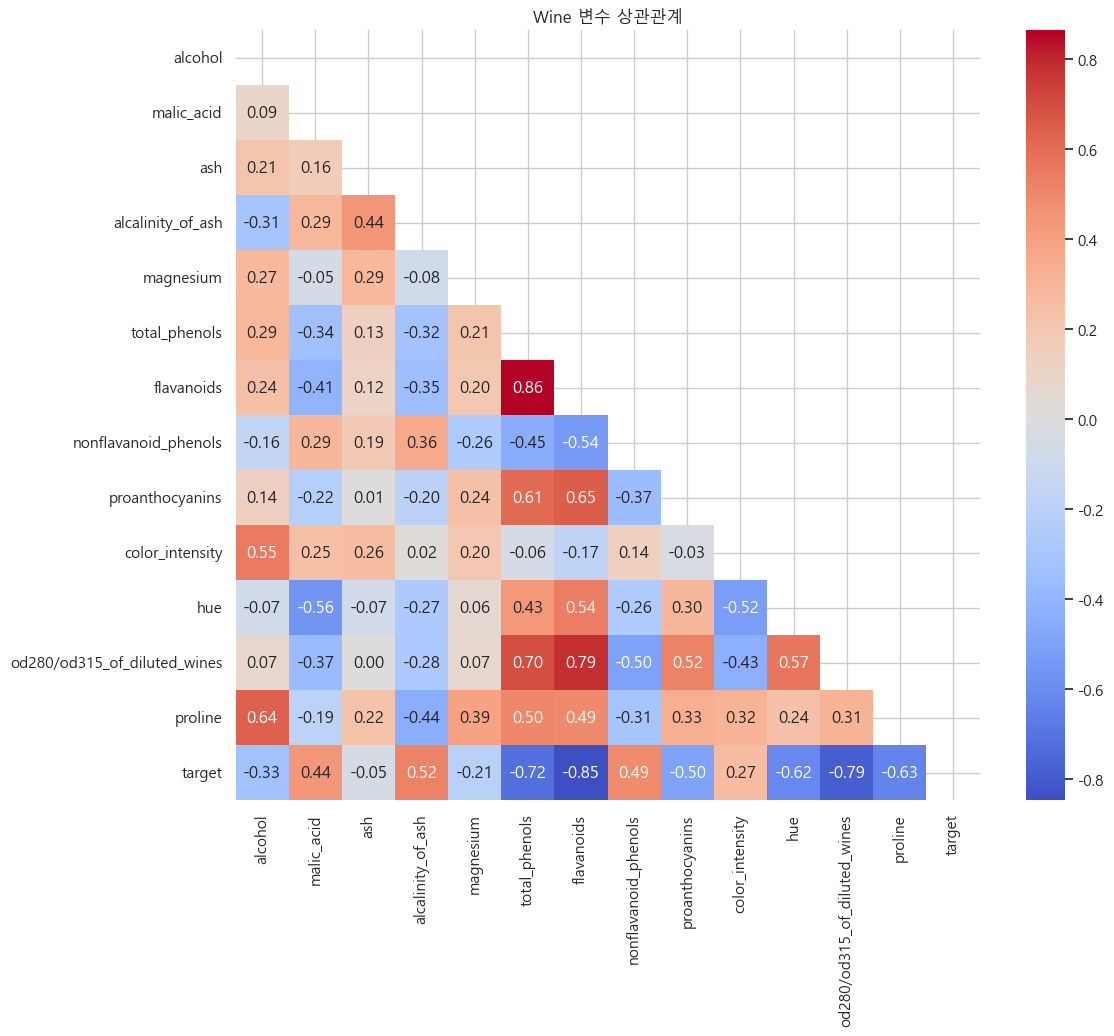

In [16]:
plt.figure(figsize=(12, 10))
corr = df[features + ['target']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool)) # 위쪽 삼각형은 중복이라 가림

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Wine 변수 상관관계')
plt.show()

# 상관계수 히트맵 (target 포함)
# flavanoids, total_phenols, od280/od315 사이 강한 양의 상관관계
# target 과는 flavanoids 등이 비교적 강한 음의 상관관계

In [17]:
fc = corr.loc[features, features]
pairs = fc.where(np.triu(np.ones(fc.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10)

# feature 쌍 중 상관계수 절댓값이 큰 상위 10개 확인
# 서로 강하게 연관된 feature 는 정보가 겹침 (다중공산성 후보, ML)

total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
flavanoids     proanthocyanins                 0.652692
alcohol        proline                         0.643720
total_phenols  proanthocyanins                 0.612413
hue            od280/od315_of_diluted_wines    0.565468
malic_acid     hue                            -0.561296
alcohol        color_intensity                 0.546364
flavanoids     hue                             0.543479
dtype: float64

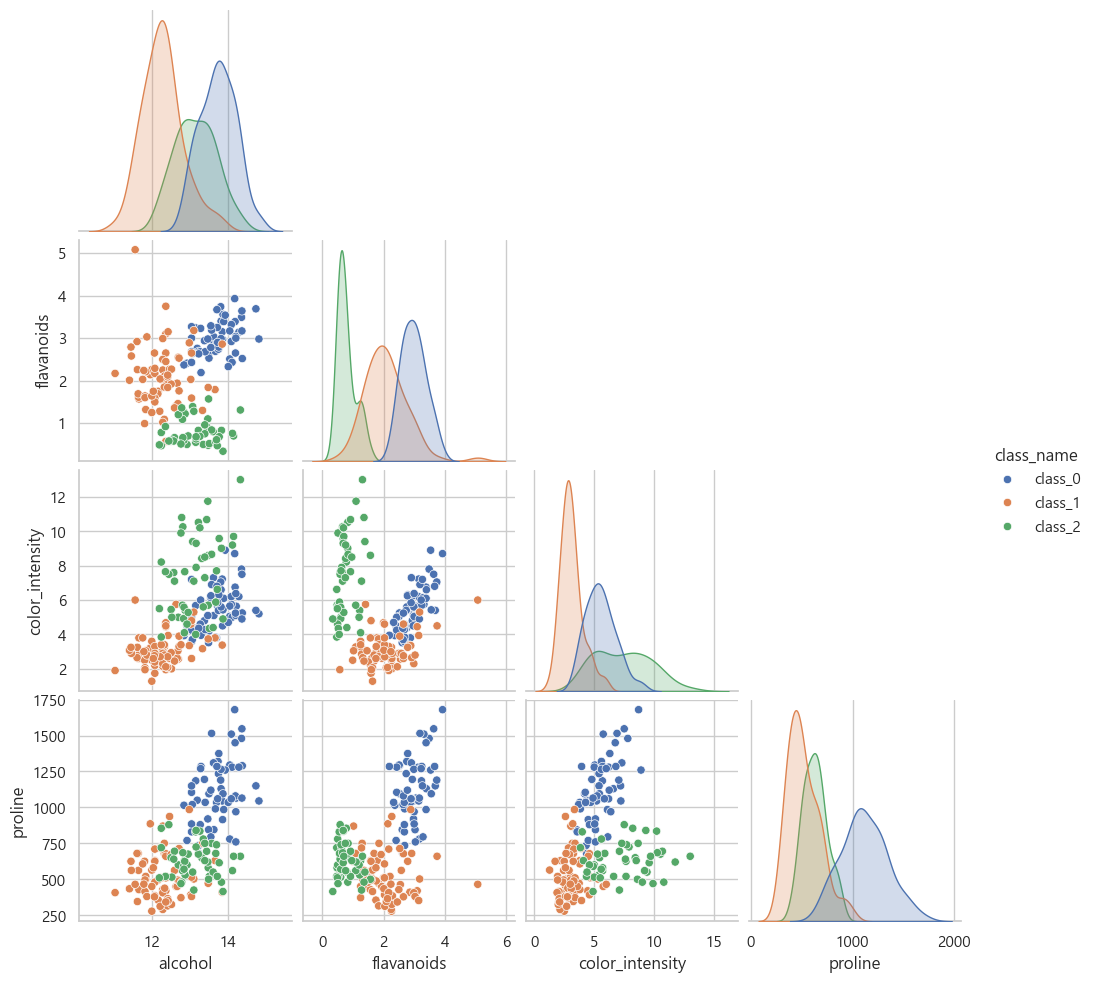

In [18]:
sns.pairplot(df, vars=['alcohol', 'flavanoids', 'color_intensity', 'proline'], hue='class_name', corner=True)
plt.show()

# 품종 구분에 유리해 보인 4개 feature 만 골라 pairplot (산점도 그래프)
# flavanoids, color_intensity 조합에서 3개 품종이 비교적 잘 분리되는 것이 보임

## 7. 스케일링 & PCA

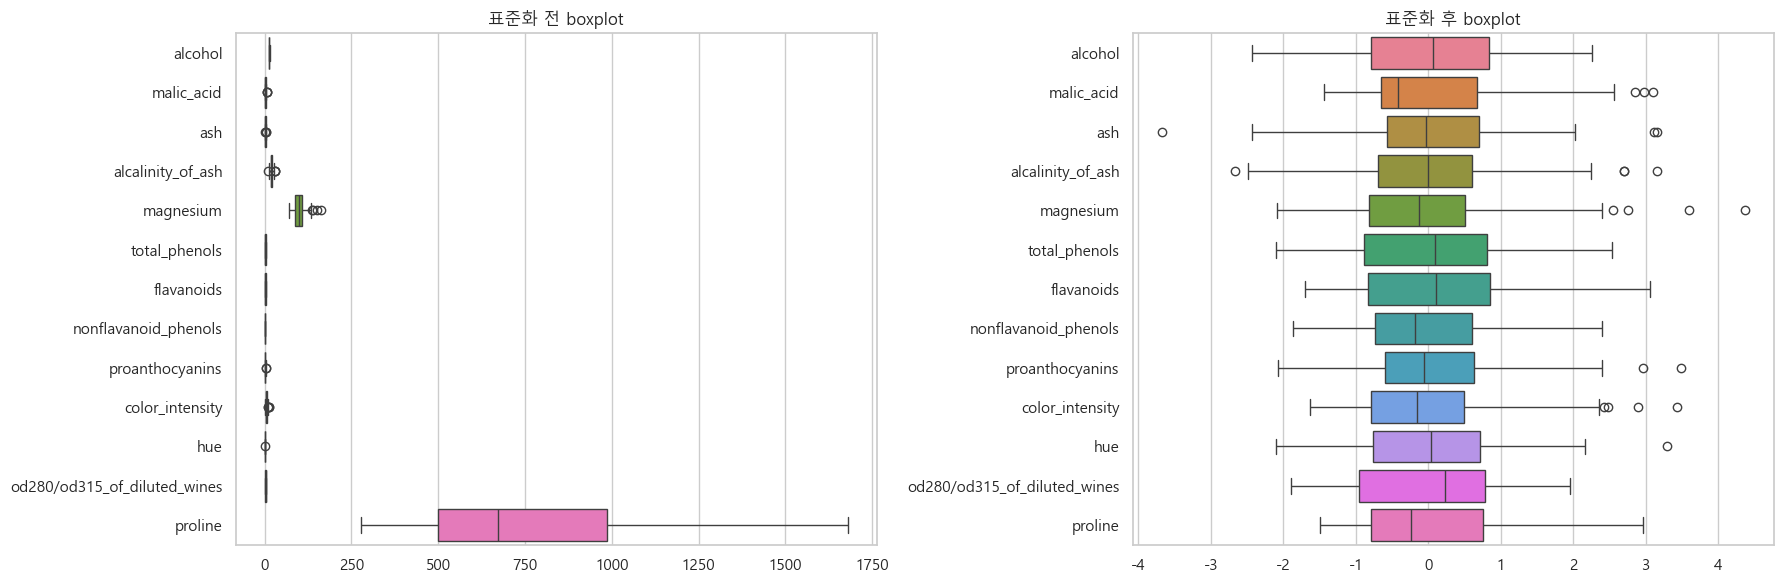

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_scaled = StandardScaler().fit_transform(df[features])
df_scaled = pd.DataFrame(X_scaled, columns=features)
# 정규화(StandardScaler): 각 feature 를 평균 0, 표준편차 1 로 맞춤

# 스케일링 전후 boxplot 나란히 비교 (피드백 반영)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.boxplot(data=df[features], orient='h', ax=axes[0])
axes[0].set_title('표준화 전 boxplot')
sns.boxplot(data=df_scaled, orient='h', ax=axes[1])
axes[1].set_title('표준화 후 boxplot')
plt.tight_layout()
plt.show()

# 왼쪽(전): proline 이 압도적으로 커서 나머지 feature 는 납작하게 눌려 보임
# 오른쪽(후): 모든 feature 가 비슷한 범위에 놓여 서로 비교 가능
# => PCA 는 분산 기준이라 스케일링 안 하면 proline 이 PC1 을 독점하게 됨

설명된 분산 비율: [0.362 0.192]


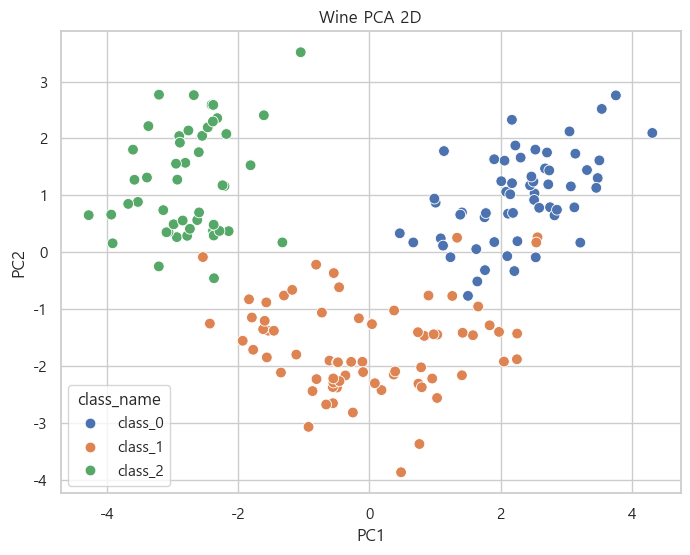

In [20]:
pca = PCA(n_components=2)
pc = pca.fit_transform(X_scaled)
print('설명된 분산 비율:', pca.explained_variance_ratio_.round(3))
# 정규화(standardscaler) => PCA로 extract => 두 축이 raw에서 얼마만큼 설명하나 보여줌
# 13d => 2d 로 압축한 결과, 두 축이 전체 분산의 절반 이상을 설명

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=df['class_name'], s=60)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Wine PCA 2D')
plt.show()

# 주성분 분석 (PCA)
# 13개 특성을 2개 특성으로 압축해 본질적 데이터 추출 후 그래프로 확인
# 3개 품종이 비교적 잘 분리되는 것을 볼 수 있음

## 8. 정리
- 결측치/중복 없음. 일부 변수(`magnesium`, `malic_acid` 등)에 소수 이상치 및 오른쪽 치우침 존재
- 변수 간 스케일 차이가 커서(`proline` 등) 표준화 필요
- `flavanoids`, `total_phenols`, `od280/od315_of_diluted_wines` 간 강한 양의 상관
- `proline`, `flavanoids`, `color_intensity`, `alcohol`이 품종 구분에 유용해 보임
- 표준화 후 PCA 2차원만으로도 3개 품종이 꽤 잘 분리됨
- 피드백 반영: 이상치 품종별 확인, 로그 변환 전후 왜도 비교, 표준화 전후 boxplot 비교 추가